The three ODE solvers which will be used are Runge-Kutta 45 (RK45) which is a standard explicit solver, Radau, which is an implicit Runge-Kutta solver, and LSODA, which is an adaptive solver which in addition to having adaptive timesteps also switches between the non-stiff Adams method and the stiff BDF method depending on how fast the stiffness it detects.

In [1]:
import time

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
from scipy.integrate import solve_ivp

runtimes = []
nsteps = []
errors = []
nfevOverSteps = []


# Lotka-Volterra
def lotka_volterra(t,y,a,b,c,d):
    R,F = y

    dRdt = a*R-b*F*R
    dFdt = c*R*F-d*F

    return [dRdt, dFdt]

a = 0.4
b = 0.001
c = 0.001
d = 0.9

# Initial conditions
y0 = [600, 400]

# Time interval
t_LV = [0, 30]

# Analytical fixed points
fixPts_LV = np.array([[0,0], [900, 400]])
n_fp_LV = fixPts_LV.shape[0]

# RK45
t_eval = np.linspace(t_LV[0],t_LV[1],1000)
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0,
    method='RK45',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)-1
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/steps_RK45
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", steps_RK45)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_RK45)


# Radau
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0,
    method='Radau',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/steps_Radau
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", steps_Radau)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_Radau)

# LSODA
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0,
    method='LSODA',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/steps_LSODA
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", steps_LSODA)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_LSODA,"\n")

# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  0.004416199983097613 s
Number of time steps taken:  18
Accuracy: Idk
nfev/timesteps:  7.444444444444445
Solver time:  0.017332199960947037 s
Number of time steps taken:  37
Accuracy: Idk
nfev/timesteps:  9.81081081081081
Solver time:  0.00241499999538064 s
Number of time steps taken:  60
Accuracy: Idk
nfev/timesteps:  2.25 

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.004416     18      0   7.444444
 Radau     0.017332     37      0   9.810811
 LSODA     0.002415     60      0   2.250000


RK45 and LSODA seem to be similar in speed for and # of function evaluations per step. Radau slower and makes more calculations per step.

In [2]:
def Belousov_Zhabotinsky(t, y, alpha, beta, gamma):
    x1,x2,x3 = y

    dx1dt = alpha*(x2+x1*(1-beta*x1-x2))
    dx2dt = 1/alpha*(x3-(1+x1)*x2)
    dx3dt = gamma*(x1-x3)

    return [dx1dt, dx2dt, dx3dt]

# Time interval
t_BZ = [0, 1000]

# Initial conditions
y0 = [1, 2, 3]

# Constants
alpha = 77.27
beta = 8.375*10**(-6)
gamma = 1.161

# Analytical fixed points
fixPts_BZ = np.array([[0,0,0], [488.88, 0.99796, 488.18], [-489.18, 1.0020, -489.18]])
n_fp_BZ = fixPts_BZ.shape[0]

t_eval = np.linspace(t_BZ[0], t_BZ[1], 1000)

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="RK45",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)-1
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/steps_RK45
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", steps_RK45)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_RK45)


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="Radau",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/steps_Radau
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", steps_Radau)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_Radau)


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/steps_LSODA
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", steps_LSODA)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_LSODA)


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  129.69298069993965 s
Number of time steps taken:  1636617
Accuracy: Idk
nfev/timesteps:  6.955214323204513
Solver time:  0.3508890999946743 s
Number of time steps taken:  577
Accuracy: Idk
nfev/timesteps:  10.8630849220104
Solver time:  0.04363480000756681 s
Number of time steps taken:  1666
Accuracy: Idk
nfev/timesteps:  2.3217286914765904
Solver  Runtime [s]   Steps  Error  nfev/step
  RK45   129.692981 1636617      0   6.955214
 Radau     0.350889     577      0  10.863085
 LSODA     0.043635    1666      0   2.321729


Huge spike at ~25s. Correct or not?

In [3]:
# Lorenz Chaos

def lorenz(t,y,sigma,rho,beta):
    [x1, x2, x3] = y

    dx1dt = sigma*(x2-x1)
    dx2dt = x1*(rho-x3)-x2
    dx3dt = x1*x2-beta*x3

    return [dx1dt, dx2dt, dx3dt]

# Constants
beta = 8/3
rho = 50
sigma = 10

# Initial conditions
x0 = [-8, 8, 27]

# Time interval
t_Lorenz = [0,20]

# Analytical fixed points
fixPts_Lorenz = np.array([[0,0,0], [7*np.sqrt(8/3), 7*np.sqrt(8/3), 49], [-7*np.sqrt(8/3), -7*np.sqrt(8/3), 49]])
n_fp_Lorenz = fixPts_Lorenz.shape[0]

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "RK45",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)-1
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/steps_RK45
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", steps_RK45)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_RK45)


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "Radau",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/steps_Radau
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", steps_Radau)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_Radau)


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/steps_LSODA
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", steps_LSODA)
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/steps_LSODA)


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  0.037387800053693354 s
Number of time steps taken:  302
Accuracy: Idk
nfev/timesteps:  8.112582781456954
Solver time:  0.23044900002423674 s
Number of time steps taken:  577
Accuracy: Idk
nfev/timesteps:  8.864818024263432
Solver time:  0.05623420001938939 s
Number of time steps taken:  1457
Accuracy: Idk
nfev/timesteps:  2.0665751544269044
Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.037388    302      0   8.112583
 Radau     0.230449    577      0   8.864818
 LSODA     0.056234   1457      0   2.066575


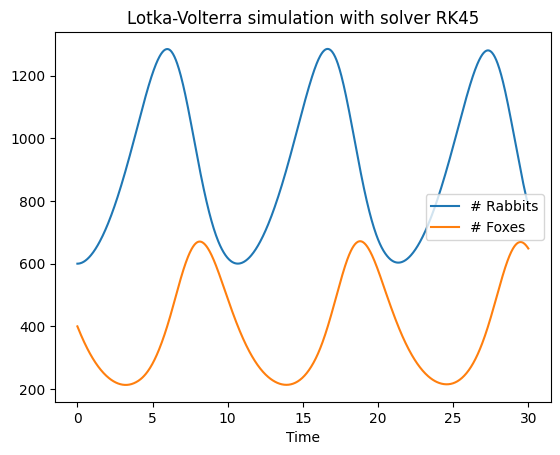

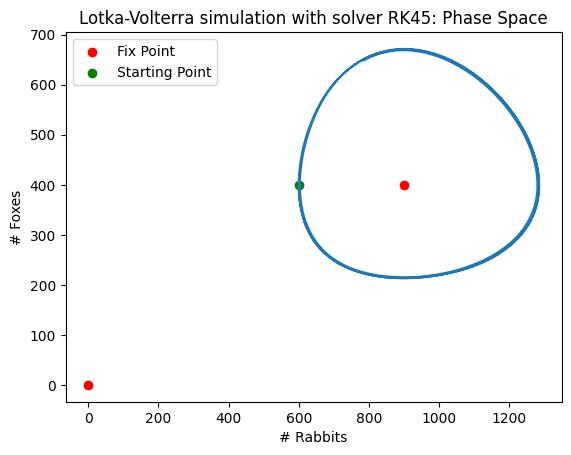

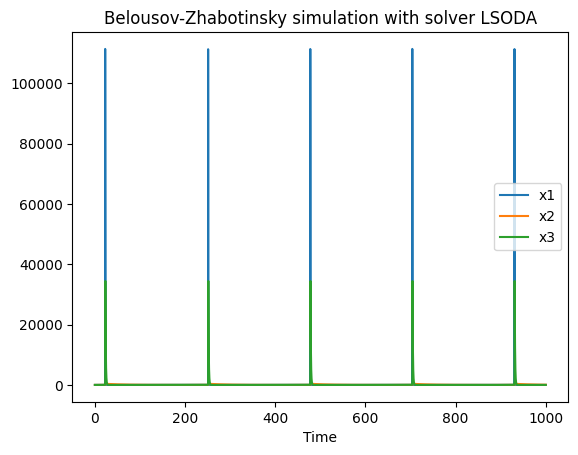

C:\Users\emilw\AppData\Local\Temp\ipykernel_16360\562920694.py:51: RuntimeWarning: divide by zero encountered in log
  fixPtsLogged = np.log(fixPts_BZ)
C:\Users\emilw\AppData\Local\Temp\ipykernel_16360\562920694.py:51: RuntimeWarning: invalid value encountered in log
  fixPtsLogged = np.log(fixPts_BZ)


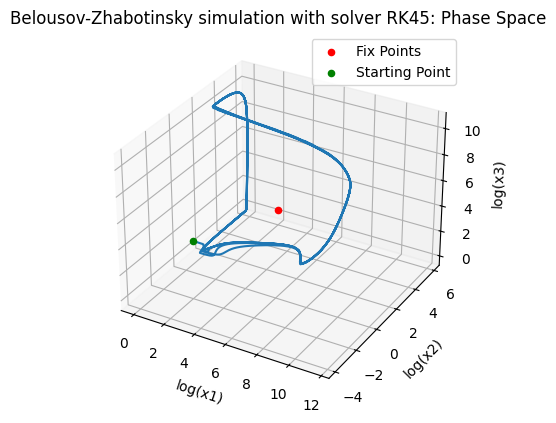

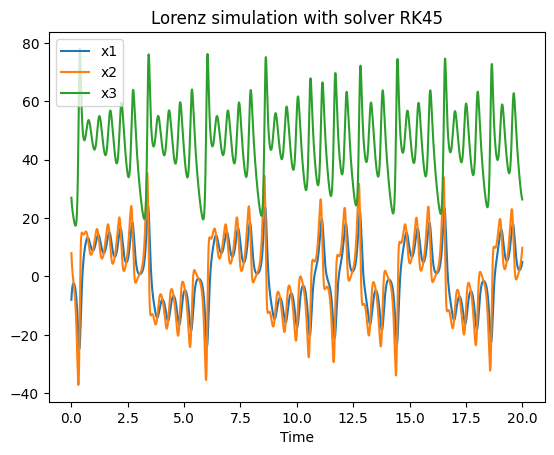

Text(0.5, 0.92, 'Lorenz simulation with solver RK45: Phase Space')

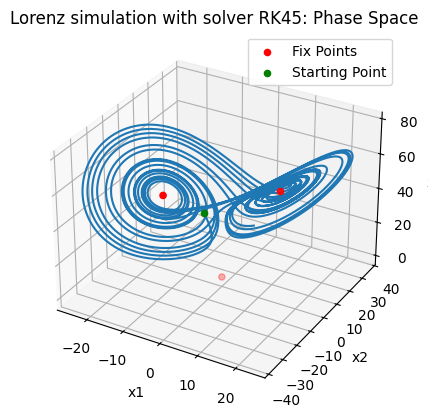

In [6]:
# Lotka-Volterra Plots

# Time Series
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_RK45(t_plot_LV) # Choose method here
plt.figure()
plt.title('Lotka-Volterra simulation with solver RK45')
plt.plot(t_plot_LV, y_plot_LV[0,:],label='# Rabbits')
plt.plot(t_plot_LV, y_plot_LV[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
plt.figure()
plt.title("Lotka-Volterra simulation with solver RK45: Phase Space")
plt.xlabel("# Rabbits")
plt.ylabel("# Foxes")
plt.plot(y_plot_LV[0,:], y_plot_LV[1,:])
plt.scatter(*fixPts_LV.T, label="Fix Point", color="r") # Fix point
plt.scatter(y_plot_LV[0,0],y_plot_LV[1,0],label="Starting Point", color="g")
plt.legend()
plt.show()

# Belousov-Zhabotinsky Plots

# Time Series
t_plot_BZ = np.linspace(t_BZ[0], t_BZ[1], 100000)
y_plot_BZ = y_BZ_LSODA(t_plot_BZ)

plt.figure()
plt.title('Belousov-Zhabotinsky simulation with solver LSODA')
plt.plot(t_plot_BZ, y_plot_BZ[0,:],label='x1')
plt.plot(t_plot_BZ, y_plot_BZ[1,:],label='x2')
plt.plot(t_plot_BZ, y_plot_BZ[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    np.log(y_plot_BZ[0,:]),
    np.log(y_plot_BZ[1,:]),
    np.log(y_plot_BZ[2,:])
)

# Fix points (log to improve visibility) (and also removes the fixed points which do not make physical sense)
fixPtsLogged = np.log(fixPts_BZ)
startPtLogged = np.log([y_plot_BZ[0,0], y_plot_BZ[1,0], y_plot_BZ[2,0]])
ax.scatter(*fixPtsLogged.T, label="Fix Points", color="r")
ax.scatter(*startPtLogged, label="Starting Point", color="g")
ax.set_xlabel('log(x1)')
ax.set_ylabel('log(x2)')
ax.set_zlabel('log(x3)')
ax.legend()
ax.set_title("Belousov-Zhabotinsky simulation with solver RK45: Phase Space")


# Lorenz Plots

# Time Series
t_plot_Lorenz = np.linspace(t_Lorenz[0], t_Lorenz[1], 10000)
y_plot_Lorenz = y_Lorenz_RK45(t_plot_Lorenz)

plt.figure()
plt.title('Lorenz simulation with solver RK45')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[0,:],label='x1')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[1,:],label='x2')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    y_plot_Lorenz[0,:],
    y_plot_Lorenz[1,:],
    y_plot_Lorenz[2,:]
)

# Fix Points
ax.scatter(*fixPts_Lorenz.T, label= "Fix Points", color="r")

ax.scatter(y_plot_Lorenz[0,0],y_plot_Lorenz[1,0],y_plot_Lorenz[2,0], label="Starting Point", color="g")
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.legend()
ax.set_title("Lorenz simulation with solver RK45: Phase Space")


 ### Multi step solvers
 Multi step solvers uses information from multiple previous time steps to make the prediction for the next time step. Single step solvers only use the previous time step. 
 Using informations from multiple steps for each prediction is more efficient/accurate. But at t=0, there is no history yet, and there is thus no information from previous steps to use. So it has to build up for some time before it reaches its full accuracy.
 So, if the integration time is short, the solver may never reach good accuracy. 
 If the solution rapidly changes, the solver may also struggle, as the information before the sudden change may be misleading.
 
 LSODA automatically switches between Adams method and BDF depending on the detected stiffness of the system. Both Adams method and BDF are multi step solvers, so LSODA can be considered a multi step solver as well.
 RK45 and Radau are both single step solvers.

In [ ]:
# Tolerance tests

